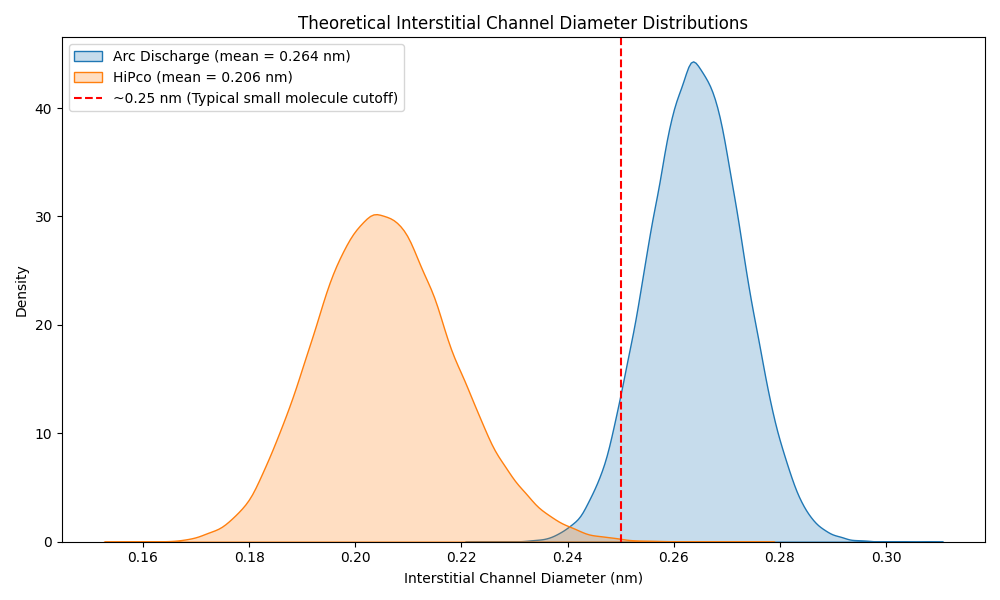

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib widget

# 1. Simulation Parameters
n_samples = 100000
vdw_gap = 0.34 # nm 

# --- Arc Discharge (Gaussian) ---
mu_arc, sigma_arc = 1.37, 0.10
# Sample triplets
d_arc = np.random.normal(loc=mu_arc, scale=sigma_arc, size=(n_samples, 3))

# --- HiPco (Log-Normal) ---
# Target mean ~ 1.0 nm, target std ~ 0.15 nm
target_mean, target_std = 1.0, 0.15
sigma_ln = np.sqrt(np.log(1 + (target_std / target_mean)**2))
mu_ln = np.log(target_mean) - (sigma_ln**2 / 2)
# Sample triplets
d_hipco = np.random.lognormal(mean=mu_ln, sigma=sigma_ln, size=(n_samples, 3))

# 2. Geometric Model (Descartes' Theorem)
def calc_interstitial_diameters(d_triplets, vdw):
    # Effective radii (geometric radius + half vdW gap)
    R = (d_triplets / 2.0) + (vdw / 2.0)
    k = 1.0 / R # Curvatures
    
    k1, k2, k3 = k[:, 0], k[:, 1], k[:, 2]
    
    # Descartes theorem for the inner Soddy circle
    k_int = k1 + k2 + k3 + 2 * np.sqrt(k1*k2 + k2*k3 + k3*k1)
    
    # The Soddy radius is the maximum free radius inside the vdW boundaries
    return 2.0 * (1.0 / k_int)

# 3. Compute distributions
d_int_arc = calc_interstitial_diameters(d_arc, vdw_gap)
d_int_hipco = calc_interstitial_diameters(d_hipco, vdw_gap)

# 4. Visualization
plt.figure(figsize=(10, 6))
sns.kdeplot(d_int_arc, fill=True, label=f'Arc Discharge (mean = {d_int_arc.mean():.3f} nm)')
sns.kdeplot(d_int_hipco, fill=True, label=f'HiPco (mean = {d_int_hipco.mean():.3f} nm)')

plt.title('Theoretical Interstitial Channel Diameter Distributions')
plt.xlabel('Interstitial Channel Diameter (nm)')
plt.ylabel('Density')
plt.axvline(0.25, color='red', linestyle='--', label='~0.25 nm (Typical small molecule cutoff)')
plt.legend()
plt.tight_layout()
plt.show()